<a href="https://colab.research.google.com/github/alldi1212/all/blob/main/praktikum_p3_fis_mamdani.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
!pip install -q scikit-fuzzy

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

%matplotlib inline

In [6]:
# Semesta pembicaraan
x_suhu   = np.arange(0, 50.01, 0.5)
x_lembap = np.arange(0, 100.01, 1)
x_kipas  = np.arange(0, 100.01, 1)

# Himpunan fuzzy
suhu = {
    "Dingin": fuzz.trapmf(x_suhu, [0, 0, 10, 20]),
    "Normal": fuzz.trimf(x_suhu, [15, 25, 35]),
    "Panas":  fuzz.trapmf(x_suhu, [30, 40, 50, 50]),
}
lembap = {
    "Kering": fuzz.trapmf(x_lembap, [0, 0, 20, 40]),
    "Sedang": fuzz.trimf(x_lembap, [30, 50, 70]),
    "Lembap": fuzz.trapmf(x_lembap, [60, 80, 100, 100]),
}
kipas = {
    "Pelan":  fuzz.trapmf(x_kipas, [0, 0, 20, 40]),
    "Sedang": fuzz.trimf(x_kipas, [30, 50, 70]),
    "Cepat":  fuzz.trapmf(x_kipas, [60, 80, 100, 100]),
}

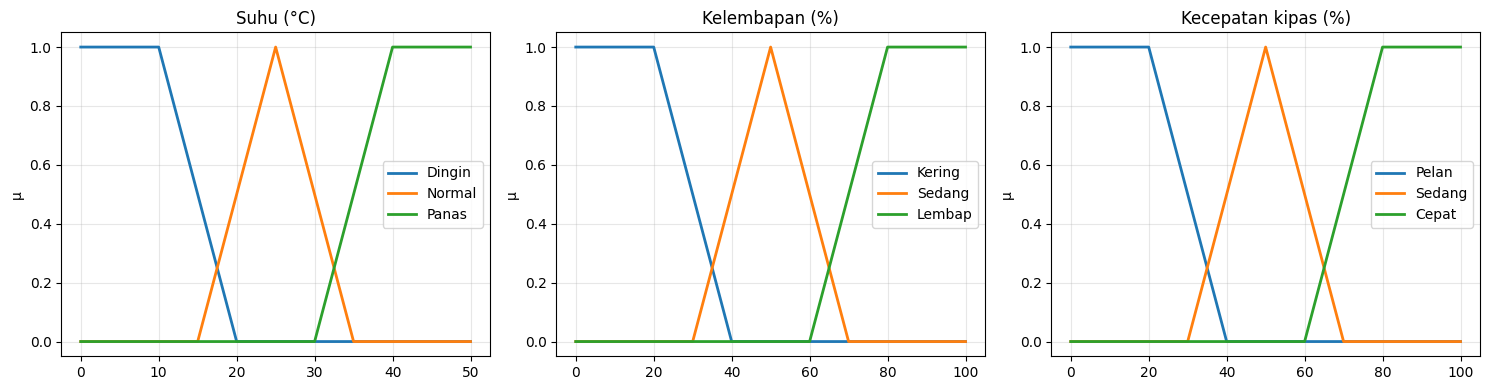

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for k, v in suhu.items():   ax[0].plot(x_suhu, v, label=k, lw=2)
ax[0].set_title("Suhu (°C)")
for k, v in lembap.items(): ax[1].plot(x_lembap, v, label=k, lw=2)
ax[1].set_title("Kelembapan (%)")
for k, v in kipas.items():  ax[2].plot(x_kipas, v, label=k, lw=2)
ax[2].set_title("Kecepatan kipas (%)")
for a in ax:
    a.legend(); a.set_ylabel("μ"); a.grid(alpha=.3)
plt.tight_layout()
plt.show()

In [8]:
rules = [  # (suhu, lembap, kipas)
    ("Dingin", "Kering", "Pelan"),  ("Dingin", "Sedang", "Pelan"),  ("Dingin", "Lembap", "Sedang"),
    ("Normal", "Kering", "Pelan"),  ("Normal", "Sedang", "Sedang"), ("Normal", "Lembap", "Cepat"),
    ("Panas",  "Kering", "Sedang"), ("Panas",  "Sedang", "Cepat"),  ("Panas",  "Lembap", "Cepat"),
]

In [9]:
T_IN, H_IN = 32, 65

mu_T = {k: float(fuzz.interp_membership(x_suhu, v, T_IN))   for k, v in suhu.items()}
mu_H = {k: float(fuzz.interp_membership(x_lembap, v, H_IN)) for k, v in lembap.items()}

print(f"Suhu {T_IN} °C       :", {k: round(v, 3) for k, v in mu_T.items()})
print(f"Kelembapan {H_IN} %  :", {k: round(v, 3) for k, v in mu_H.items()})

Suhu 32 °C       : {'Dingin': 0.0, 'Normal': 0.3, 'Panas': 0.2}
Kelembapan 65 %  : {'Kering': 0.0, 'Sedang': 0.25, 'Lembap': 0.25}


In [10]:
alphas = []
for i, (t, h, o) in enumerate(rules, 1):
    a = min(mu_T[t], mu_H[h])
    alphas.append(a)
    tanda = "  <-- menyala" if a > 0 else ""
    print(f"R{i}: IF suhu {t:6s} AND lembap {h:6s} THEN {o:6s} | alpha = {a:.3f}{tanda}")

R1: IF suhu Dingin AND lembap Kering THEN Pelan  | alpha = 0.000
R2: IF suhu Dingin AND lembap Sedang THEN Pelan  | alpha = 0.000
R3: IF suhu Dingin AND lembap Lembap THEN Sedang | alpha = 0.000
R4: IF suhu Normal AND lembap Kering THEN Pelan  | alpha = 0.000
R5: IF suhu Normal AND lembap Sedang THEN Sedang | alpha = 0.250  <-- menyala
R6: IF suhu Normal AND lembap Lembap THEN Cepat  | alpha = 0.250  <-- menyala
R7: IF suhu Panas  AND lembap Kering THEN Sedang | alpha = 0.000
R8: IF suhu Panas  AND lembap Sedang THEN Cepat  | alpha = 0.200  <-- menyala
R9: IF suhu Panas  AND lembap Lembap THEN Cepat  | alpha = 0.200  <-- menyala


In [11]:
clipped = []
agg = np.zeros_like(x_kipas, dtype=float)
for (t, h, o), a in zip(rules, alphas):
    c = np.fmin(a, kipas[o])      # clipping
    clipped.append(c)
    agg = np.fmax(agg, c)         # agregasi (max)

Kecepatan kipas (centroid) = 66.23 %


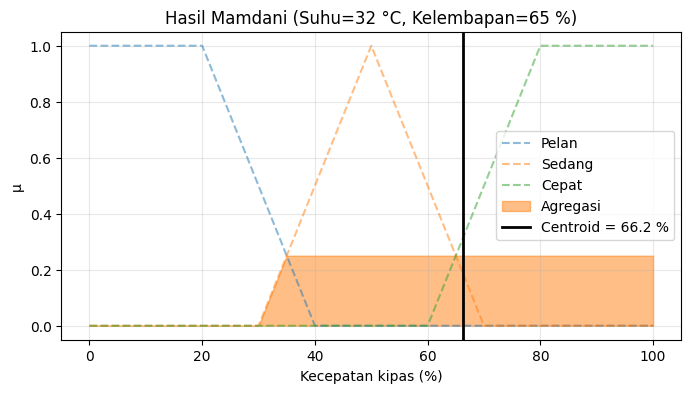

In [12]:
z_centroid = fuzz.defuzz(x_kipas, agg, "centroid")
print(f"Kecepatan kipas (centroid) = {z_centroid:.2f} %")

fig, ax = plt.subplots(figsize=(8, 4))
for k, v in kipas.items():
    ax.plot(x_kipas, v, "--", alpha=.5, label=k)
ax.fill_between(x_kipas, agg, color="tab:orange", alpha=.5, label="Agregasi")
ax.axvline(z_centroid, color="k", lw=2, label=f"Centroid = {z_centroid:.1f} %")
ax.set_title(f"Hasil Mamdani (Suhu={T_IN} °C, Kelembapan={H_IN} %)")
ax.set_xlabel("Kecepatan kipas (%)"); ax.set_ylabel("μ")
ax.legend(); ax.grid(alpha=.3)
plt.show()

In [13]:
T = ctrl.Antecedent(x_suhu, "suhu")
H = ctrl.Antecedent(x_lembap, "lembap")
F = ctrl.Consequent(x_kipas, "kipas", defuzzify_method="centroid")

for k, v in suhu.items():   T[k] = v
for k, v in lembap.items(): H[k] = v
for k, v in kipas.items():  F[k] = v

fis_rules = [ctrl.Rule(T[t] & H[h], F[o]) for t, h, o in rules]
sistem = ctrl.ControlSystem(fis_rules)

def hitung(t, h):
    sim = ctrl.ControlSystemSimulation(sistem)
    sim.input["suhu"], sim.input["lembap"] = t, h
    sim.compute()
    return sim.output["kipas"]

print(f"FIS scikit-fuzzy (T={T_IN}, H={H_IN}) = {hitung(T_IN, H_IN):.2f} %")
print(f"Mamdani manual                      = {z_centroid:.2f} %")

FIS scikit-fuzzy (T=32, H=65) = 66.23 %
Mamdani manual                      = 66.23 %


In [14]:
print(f"{'Metode':10s} | Hasil (%)")
for m in ["centroid", "bisector", "mom", "som", "lom"]:
    print(f"{m:10s} | {fuzz.defuzz(x_kipas, agg, m):6.2f}")

Metode     | Hasil (%)
centroid   |  66.23
bisector   |  66.25
mom        |  67.50
som        |  35.00
lom        | 100.00


In [15]:
uji = [(5, 10), (25, 50), (25, 90), (32, 65), (40, 20), (45, 90)]
print(f"{'Suhu':>5s} {'Lembap':>7s} {'Kipas (%)':>10s}")
for t, h in uji:
    print(f"{t:5d} {h:7d} {hitung(t, h):10.2f}")

 Suhu  Lembap  Kipas (%)
    5      10      15.56
   25      50      50.00
   25      90      84.44
   32      65      66.23
   40      20      50.00
   45      90      84.44


Rentang output: 15.6 - 84.4 %


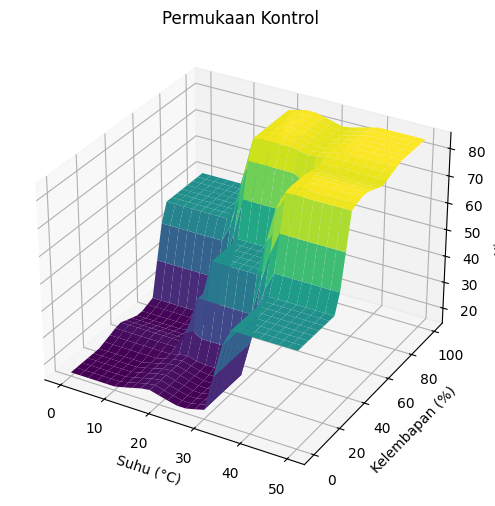

In [16]:
tt = np.linspace(0, 50, 26)
hh = np.linspace(0, 100, 26)
Z = np.array([[hitung(t, h) for t in tt] for h in hh])
print(f"Rentang output: {Z.min():.1f} - {Z.max():.1f} %")

TT, HH = np.meshgrid(tt, hh)
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(TT, HH, Z, cmap="viridis")
ax.set_xlabel("Suhu (°C)"); ax.set_ylabel("Kelembapan (%)"); ax.set_zlabel("Kipas (%)")
ax.set_title("Permukaan Kontrol")
plt.show()

Pertanyaan analisis (jawab singkat)

Mengapa hasil bagian C dan D bisa sedikit berbeda dari hitungan tangan 63,6?
Apa yang terjadi bila suatu nilai input tidak mengaktifkan satu pun aturan? Bagaimana mencegahnya?
Kapan Anda memilih centroid, dan kapan MOM?
Apa kelebihan dan keterbatasan FIS Mamdani pada kasus yang Anda rancang?


1. Kenapa bisa beda dari hitungan tangan 63,6?

Di rancangan kita, bagian C (manual) dan D (scikit-fuzzy) sebenarnya identik: 66,23 %. Jadi angka 63,6 itu kemungkinan datang dari hitungan tanganmu sendiri, dan selisihnya (sekitar 2,6) terlalu besar untuk sekadar efek numerik. Penyebab yang paling sering:

Diskretisasi. Library menghitung centroid pada titik-titik diskret (kita pakai langkah 1 %), sedangkan tangan biasanya memakai rumus kontinu. Selisihnya biasanya cuma di desimal kedua atau ketiga.
Pembulatan derajat keanggotaan di tengah jalan (misalnya 0,333 jadi 0,3).
Cara menghitung centroid yang disederhanakan, misalnya memakai rata-rata berbobot titik puncak, padahal centroid sejati memakai seluruh luas area agregasi.
Input atau parameter MF berbeda dari yang dipakai di kode.

Cara cek paling cepat: samakan dulu input dan parameter, lalu hitung ulang luas dan momen area agregasinya.

2. Kalau tidak ada aturan yang aktif?

Area agregasi jadi nol di mana-mana, sehingga centroid berubah jadi pembagian nol. scikit-fuzzy akan melempar error “Crisp output cannot be calculated”. Ibaratnya kipas dapat perintah kosong, jadi tidak tahu harus berputar seberapa.

Pencegahannya:

Pastikan himpunan input menutupi seluruh semesta dan saling overlap, sehingga tidak ada titik dengan $\mu = 0$ di semua himpunan.
Buat basis aturan lengkap (semua kombinasi, di sini 3×3 = 9 aturan).
Tambahkan aturan default sebagai cadangan jika perlu.

Di rancangan kita ini aman: Dingin–Normal–Panas menutupi 0–50 °C, dan Kering–Sedang–Lembap menutupi 0–100 %, jadi minimal satu aturan selalu menyala.

3. Kapan centroid, kapan MOM?
Centroid kupilih sebagai default untuk pengendalian halus seperti kipas. Hasilnya mulus karena mempertimbangkan seluruh bentuk area, jadi perubahan input kecil menghasilkan perubahan output kecil. Kekurangannya, hitungannya lebih berat.
MOM (mean of maximum) kupilih kalau perangkatnya terbatas (mikrokontroler) atau kalau ingin output mengikuti aturan yang paling dominan. Hitungannya ringan, tapi outputnya cenderung “melompat”.

Di kasus 32 °C / 65 %, keduanya dekat (66,23 vs 67,5), tapi untuk kipas aku tetap pilih centroid karena transisi kecepatannya lebih halus.

4. Kelebihan dan keterbatasan Mamdani di kasus ini

Kelebihan:

Aturannya mudah dibaca dan masuk akal bagi manusia (“kalau panas dan lembap, kipas kencang”).
Tidak perlu model matematis presisi.
Transisi antar kondisi mulus karena himpunan saling overlap.
Gampang disetel: cukup geser parameter MF atau ubah aturan.

Keterbatasan:

Output tidak pernah menyentuh 0 % atau 100 %. Rentangnya hanya sekitar 15,6–84,4 % akibat sifat centroid.
Ada plateau, misalnya (25, 50) dan (40, 20) sama-sama 50 %, jadi di zona itu kipas kurang peka.
Jumlah aturan membengkak. Dengan 2 input × 3 himpunan ada 9 aturan, tapi menambah satu input saja sudah jadi 27.
Penyetelan masih coba-coba, tanpa jaminan hasilnya optimal.
Tidak belajar dari data. Kalau butuh yang adaptif, lihat Sugeno atau ANFIS.

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

# 1. Definisi Semesta Pembicaraan
x_cahaya_alt = np.arange(0, 1001, 10)
x_orang_alt = np.arange(0, 11, 1)
x_kecerahan_alt = np.arange(0, 101, 1)

# 2. Membuat Antecedent dan Consequent
cahaya_sekitar_alt = ctrl.Antecedent(x_cahaya_alt, 'cahaya_sekitar_alt')
jumlah_orang_alt = ctrl.Antecedent(x_orang_alt, 'jumlah_orang_alt')
kecerahan_lampu_alt = ctrl.Consequent(x_kecerahan_alt, 'kecerahan_lampu_alt')

# 3. Definisi Fungsi Keanggotaan
cahaya_sekitar_alt['Gelap']  = fuzz.trapmf(x_cahaya_alt, [0, 0, 150, 350])
cahaya_sekitar_alt['Redup']  = fuzz.trimf(x_cahaya_alt, [200, 450, 700])
cahaya_sekitar_alt['Terang'] = fuzz.trapmf(x_cahaya_alt, [550, 800, 1000, 1000])

jumlah_orang_alt['Sepi']   = fuzz.trapmf(x_orang_alt, [0, 0, 1, 3])
jumlah_orang_alt['Sedang'] = fuzz.trimf(x_orang_alt, [2, 5, 8])
jumlah_orang_alt['Ramai']  = fuzz.trapmf(x_orang_alt, [6, 8, 10, 10])

kecerahan_lampu_alt['Redup']  = fuzz.trapmf(x_kecerahan_alt, [0, 0, 20, 45])
kecerahan_lampu_alt['Sedang'] = fuzz.trimf(x_kecerahan_alt, [30, 55, 80])
kecerahan_lampu_alt['Terang'] = fuzz.trapmf(x_kecerahan_alt, [65, 85, 100, 100])

# 4. Aturan
rules_lampu_alt = [
    ctrl.Rule(cahaya_sekitar_alt['Gelap'] & jumlah_orang_alt['Sepi'], kecerahan_lampu_alt['Sedang']),
    ctrl.Rule(cahaya_sekitar_alt['Gelap'] & jumlah_orang_alt['Sedang'], kecerahan_lampu_alt['Terang']),
    ctrl.Rule(cahaya_sekitar_alt['Gelap'] & jumlah_orang_alt['Ramai'], kecerahan_lampu_alt['Terang']),
    ctrl.Rule(cahaya_sekitar_alt['Redup'] & jumlah_orang_alt['Sepi'], kecerahan_lampu_alt['Redup']),
    ctrl.Rule(cahaya_sekitar_alt['Redup'] & jumlah_orang_alt['Sedang'], kecerahan_lampu_alt['Sedang']),
    ctrl.Rule(cahaya_sekitar_alt['Redup'] & jumlah_orang_alt['Ramai'], kecerahan_lampu_alt['Terang']),
    ctrl.Rule(cahaya_sekitar_alt['Terang'] & jumlah_orang_alt['Sepi'], kecerahan_lampu_alt['Redup']),
    ctrl.Rule(cahaya_sekitar_alt['Terang'] & jumlah_orang_alt['Sedang'], kecerahan_lampu_alt['Redup']),
    ctrl.Rule(cahaya_sekitar_alt['Terang'] & jumlah_orang_alt['Ramai'], kecerahan_lampu_alt['Sedang'])
]

sistem_lampu_alt = ctrl.ControlSystem(rules_lampu_alt)
sim_lampu_alt = ctrl.ControlSystemSimulation(sistem_lampu_alt)

# Simulasi Skenario Uji
sim_lampu_alt.input['cahaya_sekitar_alt'] = 250
sim_lampu_alt.input['jumlah_orang_alt'] = 6
sim_lampu_alt.compute()

print(f"Hasil Simulasi Uji (Cahaya=250 Lux, Jumlah Orang=6): {sim_lampu_alt.output['kecerahan_lampu_alt']:.2f}%")


Hasil Simulasi Uji (Cahaya=250 Lux, Jumlah Orang=6): 73.80%
